# Second-Chern-form density $c_2(\mathbf k)$ behind a $d\theta/dQ$

Recall the definition of the second Chern form in terms of the Berry curvature $F$:

$$
c_2 = \frac{1}{32\pi^2} \epsilon^{ijkl} \text{Tr}[F_{ij} F_{kl}]
$$

and the axion response $d\theta/dQ$ as the integral of $c_2$ over the Brillouin zone:

$$
d\theta/dQ = \int_{\text{BZ}} c_2(\mathbf k) \, d^3k
$$


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "axion_phonon/axion.py").exists())
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))

`archive/code/run_axion.py` saves the density with every dθ:

- `<mode run>/<sweep>/nk_<N>.npz` holds `c2_density` (nk, nk, nk, 2) for the base and mode ends of the
finite difference, and `dtheta = Σ_k c2 · d3k`. 
- `SWEEPS` maps a label to a sweep folder, as in `dtheta_vs_nk.ipynb`; each gets one row of $k_3$ planes.

In [3]:
# dtheta sweeps saved by run_axion.py (in the displaced run's folder), {label: folder}
M = DATA / "Y2Ir2O7/phonon/GM2-"
SWEEPS = {
    "mode 1, LDA": M / "mode1/Q_0.01A/lda/w90_trial02_212982/nk_sweep_tif_shared_ws",
    "mode 1, PBE": M / "mode1/Q_0.01A/pbe/w90_trial02_212996/nk_sweep_tif_shared_ws",
    "mode 2, LDA": M / "mode2/Q_0.01A/lda/w90_trial02_212994/nk_sweep_tif_shared_ws",
    "mode 3, LDA": M / "mode3/Q_0.01A/lda/w90_trial02_212995/nk_sweep_tif_shared_ws",
    "mode 3, PBE": M / "mode3/Q_0.01A/pbe/w90_trial02_213002/nk_sweep_tif_shared_ws",
}

NK = 12
END = "mean"    # 0: base end, 1: mode end, "mean": their average (what dθ/dQ reports)
SLICES = 6      # k3 planes to show
# colour range: "row" (each sweep its own), "mode" (shared by rows with the same
# label before the comma, e.g. LDA vs PBE of one mode), "all"
SCALE = "mode"  

In [4]:
def load_c2(folder, nk, end):
    data = np.load(folder / f"nk_{nk}.npz", allow_pickle=True)
    c2_all = (data["c2_density"] if "c2_density" in data.files else data["chern2_density"]).real
    c2 = c2_all.mean(axis=-1) if end == "mean" else c2_all[..., end]
    d3k = float(data["d3k"]) if "d3k" in data.files else 1 / nk**3
    return c2, d3k


C2 = {}
for label, folder in SWEEPS.items():
    c2, d3k = load_c2(folder, NK, END)
    C2[label] = (c2, d3k)
    print(f"{label:14s} nk={NK} end={END}: sum(c2)*d3k = {c2.sum() * d3k:+.5f} rad/Å,  max|c2| = {np.abs(c2).max():.3g}")

mode 1, LDA    nk=12 end=mean: sum(c2)*d3k = -0.01804 rad/Å,  max|c2| = 0.0844
mode 1, PBE    nk=12 end=mean: sum(c2)*d3k = -0.01756 rad/Å,  max|c2| = 0.0716
mode 2, LDA    nk=12 end=mean: sum(c2)*d3k = +0.05417 rad/Å,  max|c2| = 0.452
mode 3, LDA    nk=12 end=mean: sum(c2)*d3k = +0.06549 rad/Å,  max|c2| = 0.146
mode 3, PBE    nk=12 end=mean: sum(c2)*d3k = +0.05847 rad/Å,  max|c2| = 0.141


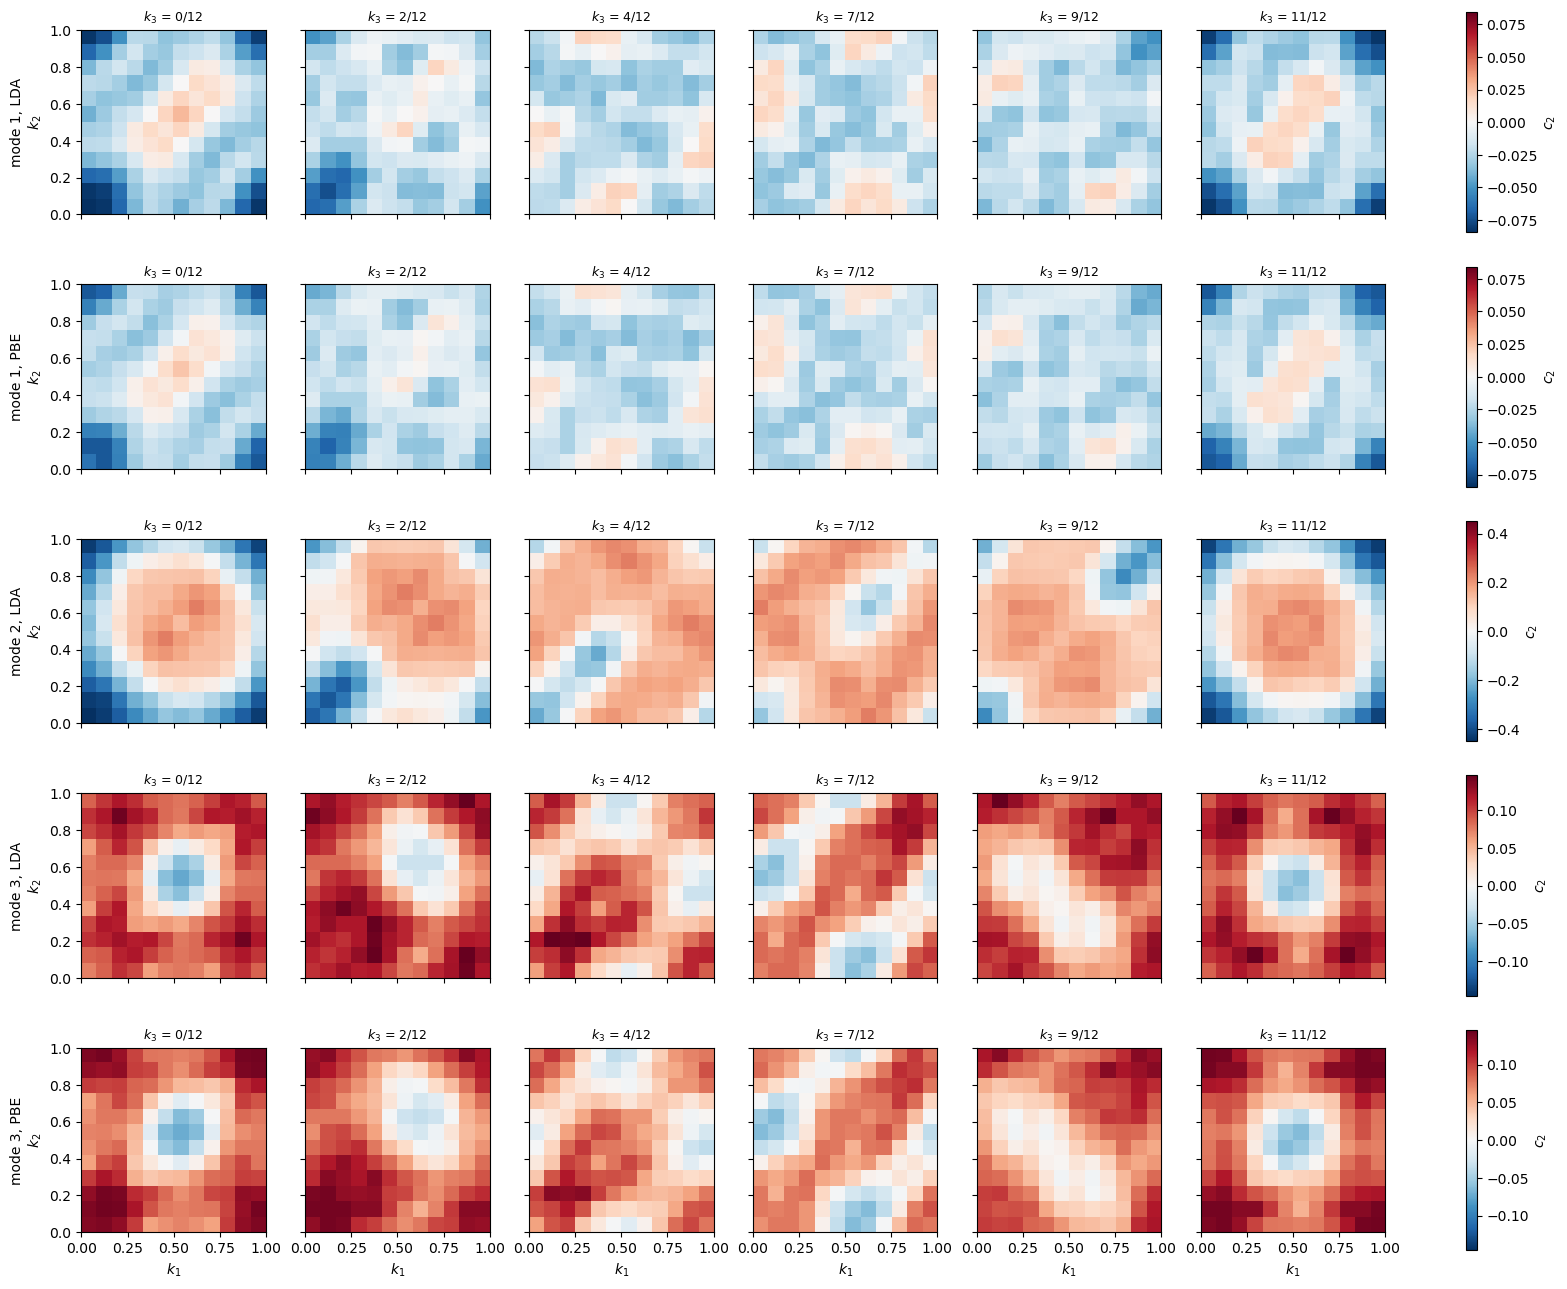

In [4]:
group = lambda label: label.split(",")[0] if SCALE == "mode" else (label if SCALE == "row" else "all")
vmax = {}
for label, (c2, _) in C2.items():
    vmax[group(label)] = max(vmax.get(group(label), 0), np.abs(c2).max())

planes = np.linspace(0, NK - 1, SLICES).round().astype(int)
fig, axes = plt.subplots(len(C2), SLICES, figsize=(2.6 * SLICES, 2.6 * len(C2)), squeeze=False,
                         sharex=True, sharey=True, constrained_layout=True)
for row, (label, (c2, d3k)) in zip(axes, C2.items()):
    v = vmax[group(label)]
    for ax, k3 in zip(row, planes):
        image = ax.imshow(c2[:, :, k3].T, origin="lower", extent=(0, 1, 0, 1), cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title(f"$k_3$ = {k3}/{NK}", fontsize=9)
    row[0].set_ylabel(f"{label}\n$k_2$")
    fig.colorbar(image, ax=row, shrink=0.9, label="$c_2$")
for ax in axes[-1]:
    ax.set_xlabel("$k_1$")
plt.show()

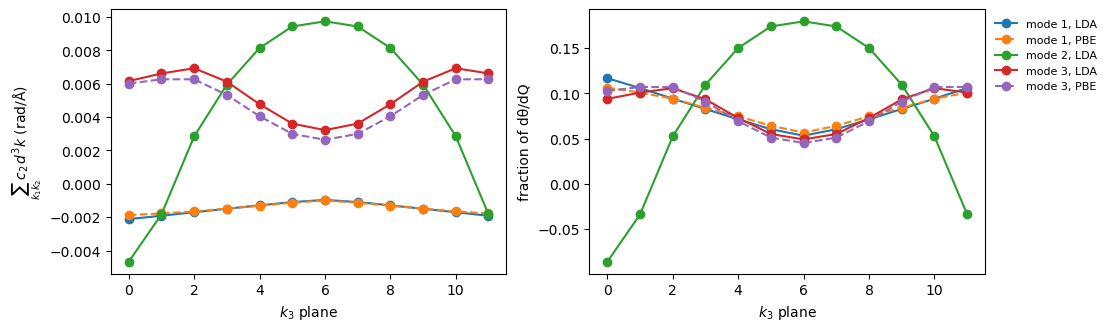

In [5]:
# Where the integral comes from: the signed c2 summed over each k3 plane (adds up to dθ/dQ)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
for i, (label, (c2, d3k)) in enumerate(C2.items()):
    style = "--" if "PBE" in label else "-"
    profile = c2.sum(axis=(0, 1)) * d3k
    axes[0].plot(profile, "o" + style, color=f"C{i}", label=label)
    axes[1].plot(profile / profile.sum(), "o" + style, color=f"C{i}", label=label)
axes[0].set(xlabel="$k_3$ plane", ylabel=r"$\sum_{k_1 k_2} c_2\,d^3k$ (rad/Å)")
axes[1].set(xlabel="$k_3$ plane", ylabel="fraction of dθ/dQ")
axes[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()